<a href="https://colab.research.google.com/github/priyankaraguramr-cmyk/online-shopper-purchase-Behaviour-analysis-using-python/blob/main/Online_Shoppers__EDA_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Online Shoppers Purchasing Behaviour - EDA Project
**Domain:** Sales and E-commerce

## Task 1 - Problem Definition and Dataset Selection

### Problem statement

Many people visit an online store but only a few of them actually buy something. Every visitor who leaves without buying is a lost sale, and the money spent on bringing that visitor to the site is also wasted. In this project I look at the browsing sessions of an online shop to find out which behaviours are linked to a purchase, so that the shop can improve its conversion rate.

**Questions I want to answer**
- How many sessions end in a purchase?
- Which months and visitor types buy more?
- How do page value, bounce rate and exit rate affect buying?
- Does viewing more product pages help?

### Dataset information

**Source:** UCI Machine Learning Repository - Online Shoppers Purchasing Intention Dataset
https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset

The data has 12,330 rows and 18 columns (more than the minimum of 500 rows and 10 columns). It has numerical columns like page counts and time spent, and categorical columns like month and visitor type. Each row is one session (one visit to the website).

| Column | Meaning |
|---|---|
| Administrative, Informational, ProductRelated | number of pages of each type visited |
| Administrative_Duration, Informational_Duration, ProductRelated_Duration | time spent on those pages (seconds) |
| BounceRates, ExitRates | how often visitors leave the site |
| PageValues | average value of the pages visited before a purchase |
| SpecialDay | how close the visit is to a special day (0 to 1) |
| Month, OperatingSystems, Browser, Region, TrafficType, VisitorType, Weekend | details of the visit |
| Revenue | True if the session ended in a purchase |

### Importing libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')

### Loading the data
The csv file is uploaded in the Colab files section, so it is read directly from there.

In [ ]:
df = pd.read_csv("online_shoppers_intention.csv")
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


### Initial overview

In [ ]:
# number of rows and columns
print('Rows:', df.shape[0])
print('Columns:', df.shape[1])

Rows: 12330
Columns: 18


In [ ]:
# column names, data types and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

In [ ]:
# summary statistics of the numerical columns
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.315166,3.321784,0.0,0.000000,1.000000,4.000000,27.000000
Administrative_Duration,12330.0,80.818611,176.779107,0.0,0.000000,7.500000,93.256250,3398.750000
Informational,12330.0,0.503569,1.270156,0.0,0.000000,0.000000,0.000000,24.000000
Informational_Duration,12330.0,34.472398,140.749294,0.0,0.000000,0.000000,0.000000,2549.375000
ProductRelated,12330.0,31.731468,44.475503,0.0,7.000000,18.000000,38.000000,705.000000
ProductRelated_Duration,12330.0,1194.746220,1913.669288,0.0,184.137500,598.936905,1464.157214,63973.522230
BounceRates,12330.0,0.022191,0.048488,0.0,0.000000,0.003112,0.016813,0.200000
ExitRates,12330.0,0.043073,0.048597,0.0,0.014286,0.025156,0.050000,0.200000
PageValues,12330.0,5.889258,18.568437,0.0,0.000000,0.000000,0.000000,361.763742
SpecialDay,12330.0,0.061427,0.198917,0.0,0.000000,0.000000,0.000000,1.000000


In [ ]:
# missing values in each column
df.isnull().sum()

,0
Administrative,0
Administrative_Duration,0
Informational,0
Informational_Duration,0
ProductRelated,0
ProductRelated_Duration,0
BounceRates,0
ExitRates,0
PageValues,0
SpecialDay,0


In [ ]:
# duplicate rows
print('Duplicate rows:', df.duplicated().sum())

Duplicate rows: 125


**Observations**
- 12,330 rows and 18 columns
- no missing values
- 125 duplicate rows, which I will remove
- Revenue and Weekend are True/False. OperatingSystems, Browser, Region and TrafficType are numbers but they are only codes
- the duration columns and PageValues have a very large maximum compared to the mean, so they are skewed

## Task 2 - Data Cleaning and Pre-processing

### Missing values

In [ ]:
duration_cols = ['Administrative_Duration', 'Informational_Duration', 'ProductRelated_Duration']

print('Missing values:', df.isnull().sum().sum())
print('Negative durations:', (df[duration_cols] < 0).sum().sum())

Missing values: 0
Negative durations: 0


There are no missing values and no negative times, so nothing needs to be filled or dropped.

### Duplicates

In [ ]:
print('Rows before:', len(df))
df = df.drop_duplicates().reset_index(drop=True)
print('Rows after:', len(df))

Rows before: 12330
Rows after: 12205


125 duplicate rows were removed because they would count the same session twice.

### Renaming columns
Some column names are very long, so I made them shorter. Revenue is renamed to Purchased because it shows whether the visitor purchased.

In [ ]:
df = df.rename(columns={
    'Administrative': 'Admin_Pages',
    'Administrative_Duration': 'Admin_Duration',
    'Informational': 'Info_Pages',
    'Informational_Duration': 'Info_Duration',
    'ProductRelated': 'Product_Pages',
    'ProductRelated_Duration': 'Product_Duration',
    'BounceRates': 'Bounce_Rate',
    'ExitRates': 'Exit_Rate',
    'PageValues': 'Page_Value',
    'SpecialDay': 'Special_Day',
    'OperatingSystems': 'OS',
    'TrafficType': 'Traffic_Type',
    'VisitorType': 'Visitor_Type',
    'Revenue': 'Purchased'
})

### Changing data types

In [ ]:
# True/False to 1/0
df['Purchased'] = df['Purchased'].astype(int)
df['Weekend'] = df['Weekend'].astype(int)

In [ ]:
# these columns are only codes, so they are changed to category
for col in ['OS', 'Browser', 'Region', 'Traffic_Type']:
    df[col] = df[col].astype('category')

In [ ]:
df.dtypes

,0
Admin_Pages,int64
Admin_Duration,float64
Info_Pages,int64
Info_Duration,float64
Product_Pages,int64
Product_Duration,float64
Bounce_Rate,float64
Exit_Rate,float64
Page_Value,float64
Special_Day,float64


Purchased and Weekend are now 0/1, so the mean of Purchased directly gives the conversion rate. OS, Browser, Region and Traffic_Type are category because the numbers are only labels.

### Creating new columns

In [ ]:
# total pages and total time of each session
df['Total_Pages'] = df['Admin_Pages'] + df['Info_Pages'] + df['Product_Pages']
df['Total_Duration'] = df['Admin_Duration'] + df['Info_Duration'] + df['Product_Duration']

# average time per page (0 when no pages were seen)
df['Avg_Time_Per_Page'] = np.where(df['Total_Pages'] > 0, df['Total_Duration'] / df['Total_Pages'], 0)

In [ ]:
# months in calendar order for the charts (January and April are not in the data)
month_order = ['Feb', 'Mar', 'May', 'June', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

# season from month
season_map = {'Dec': 'Winter', 'Feb': 'Winter',
              'Mar': 'Spring', 'May': 'Spring',
              'June': 'Summer', 'Jul': 'Summer', 'Aug': 'Summer',
              'Sep': 'Autumn', 'Oct': 'Autumn', 'Nov': 'Autumn'}
df['Season'] = df['Month'].map(season_map)

In [ ]:
# engagement level from the number of product pages viewed
df['Engagement'] = pd.cut(df['Product_Pages'],
                          bins=[-1, 10, 30, 60, 10000],
                          labels=['Low', 'Medium', 'High', 'Very High'])

df[['Total_Pages', 'Total_Duration', 'Avg_Time_Per_Page', 'Season', 'Engagement']].head()

,Total_Pages,Total_Duration,Avg_Time_Per_Page,Season,Engagement
0,1,0.000000,0.000000,Winter,Low
1,2,64.000000,32.000000,Winter,Low
2,1,0.000000,0.000000,Winter,Low
3,2,2.666667,1.333333,Winter,Low
4,10,627.500000,62.750000,Winter,Low


Added total pages, total duration, average time per page, season and an engagement level (Low, Medium, High, Very High) based on how many product pages were viewed.

### Outliers and skewness

In [ ]:
skew_cols = ['Admin_Duration', 'Info_Duration', 'Product_Duration', 'Page_Value', 'Bounce_Rate', 'Exit_Rate']
df[skew_cols].skew()

,0
Admin_Duration,5.592152
Info_Duration,7.540291
Product_Duration,7.253161
Page_Value,6.350983
Bounce_Rate,3.162425
Exit_Rate,2.234645


The duration columns and Page_Value are highly skewed (above 5). I am keeping the outliers because they are real customers who browsed a lot, and many of them are buyers. Removing them would hide the buying pattern. I only use a log transformation to reduce the skew.

In [ ]:
# log1p is used because many values are 0
df['Log_Product_Duration'] = np.log1p(df['Product_Duration'])
df['Log_Page_Value'] = np.log1p(df['Page_Value'])

print('Product_Duration skew after log:', round(df['Log_Product_Duration'].skew(), 2))
print('Page_Value skew after log:', round(df['Log_Page_Value'].skew(), 2))

Product_Duration skew after log: -1.43
Page_Value skew after log: 1.79


The skew came down a lot after the log. Page_Value is still skewed because most sessions have a value of 0.

### Grouping the data

In [ ]:
# average values for buyers and non-buyers
df.groupby('Purchased')[['Page_Value', 'Product_Pages', 'Product_Duration', 'Bounce_Rate', 'Exit_Rate']].mean().round(2)

,Page_Value,Product_Pages,Product_Duration,Bounce_Rate,Exit_Rate
Purchased,,,,,
0,2.00,29.05,1082.98,0.02,0.05
1,27.26,48.21,1876.21,0.01,0.02


In [ ]:
print('Overall conversion rate:', round(df['Purchased'].mean() * 100, 2), '%')

Overall conversion rate: 15.63 %


After cleaning there are 12,205 rows and the overall conversion rate is about 15.6%. Buyers have a much higher page value and view more product pages.

## Task 3 - EDA and Visualizations

### Univariate analysis

**Chart 1 - Purchase outcome and visitor types**

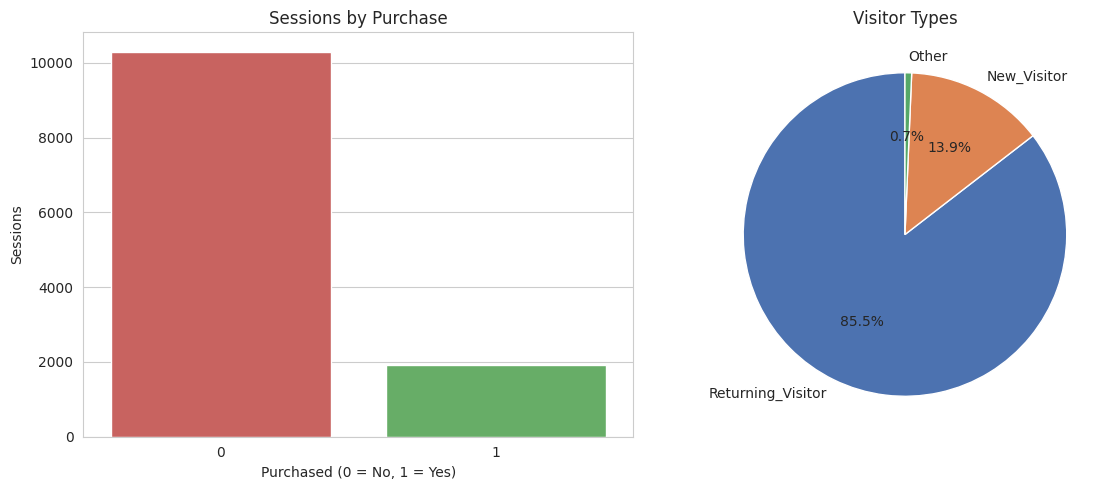

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# purchase count
sns.countplot(x='Purchased', data=df, palette=['#d9534f', '#5cb85c'], ax=ax[0])
ax[0].set_title('Sessions by Purchase')
ax[0].set_xlabel('Purchased (0 = No, 1 = Yes)')
ax[0].set_ylabel('Sessions')

# visitor types
df['Visitor_Type'].value_counts().plot.pie(autopct='%1.1f%%', startangle=90,
                                           colors=['#4c72b0', '#dd8452', '#55a868'], ax=ax[1])
ax[1].set_title('Visitor Types')
ax[1].set_ylabel('')

plt.tight_layout()
plt.show()

**Interpretation:** Only about 15.6% of the sessions end in a purchase, so more than 8 out of 10 visitors leave without buying. About 85% of the visitors are returning visitors, around 14% are new and less than 1% are Other, so the shop depends mostly on people who already know it.

**Chart 2 - Time spent on product pages**

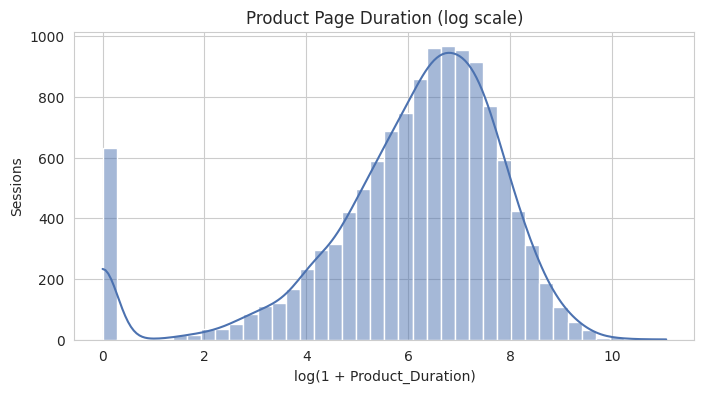

In [ ]:
plt.figure(figsize=(8, 4))
sns.histplot(df['Log_Product_Duration'], bins=40, kde=True, color='#4c72b0')
plt.title('Product Page Duration (log scale)')
plt.xlabel('log(1 + Product_Duration)')
plt.ylabel('Sessions')
plt.show()

**Interpretation:** I used the log scale because the raw values were too skewed. There is a small bar on the left for sessions with no time on product pages, and the rest looks like a bell shape.

**Chart 3 - Product pages viewed**

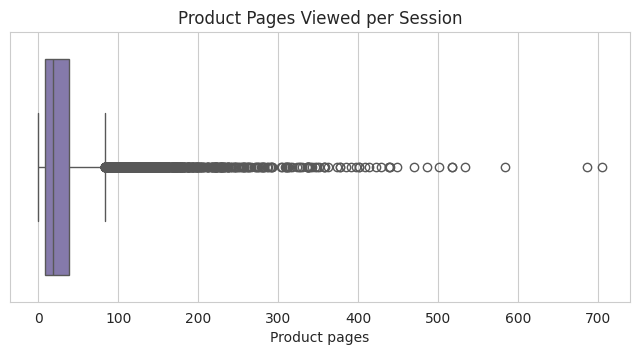

In [ ]:
plt.figure(figsize=(8, 3.5))
sns.boxplot(x=df['Product_Pages'], color='#8172b3')
plt.title('Product Pages Viewed per Session')
plt.xlabel('Product pages')
plt.show()

**Interpretation:** Most sessions view between 8 and 38 product pages, but there are many outliers going up to about 700 pages. These are heavy browsers and I kept them.

**Chart 4 - Sessions per month**

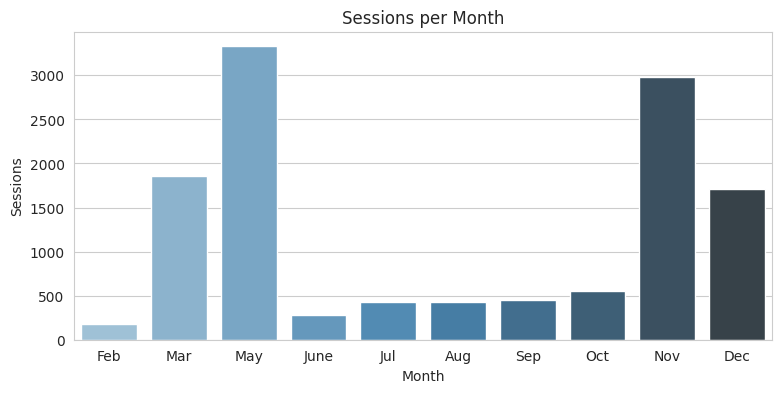

In [ ]:
plt.figure(figsize=(9, 4))
sns.countplot(x='Month', data=df, order=month_order, palette='Blues_d')
plt.title('Sessions per Month')
plt.xlabel('Month')
plt.ylabel('Sessions')
plt.show()

**Interpretation:** May has the highest traffic (about 3,300 sessions), followed by November, March and December. February has the lowest with only 181 sessions.

### Bivariate analysis

**Chart 5 - Conversion rate by month**

In [ ]:
month_rate = (df.groupby('Month')['Purchased'].mean() * 100).reindex(month_order)
month_rate.round(1)

,Purchased
Month,
Feb,1.7
Mar,10.3
May,11.0
June,10.2
Jul,15.3
Aug,17.6
Sep,19.2
Oct,20.9
Nov,25.5


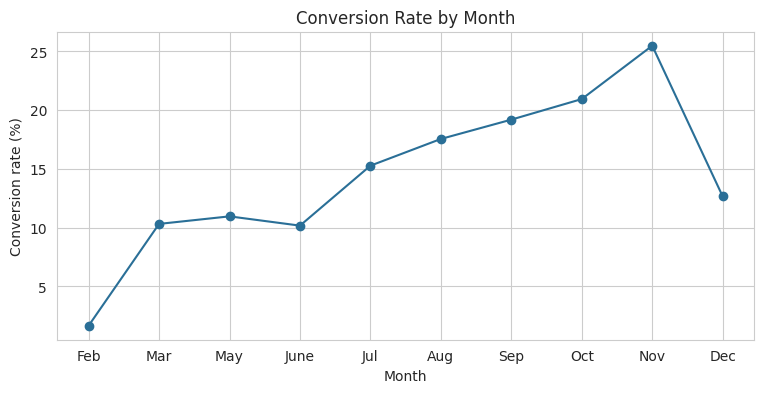

In [ ]:
plt.figure(figsize=(9, 4))
plt.plot(month_order, month_rate.values, marker='o', color='#2a6f97')
plt.title('Conversion Rate by Month')
plt.xlabel('Month')
plt.ylabel('Conversion rate (%)')
plt.show()

**Interpretation:** November is the best month with about 25.5% conversion, then October (20.9%) and September (19.2%). February is only 1.7%. May has the most traffic but only about 11% conversion, so many people come in May and do not buy.

**Chart 6 - Conversion rate by visitor type**

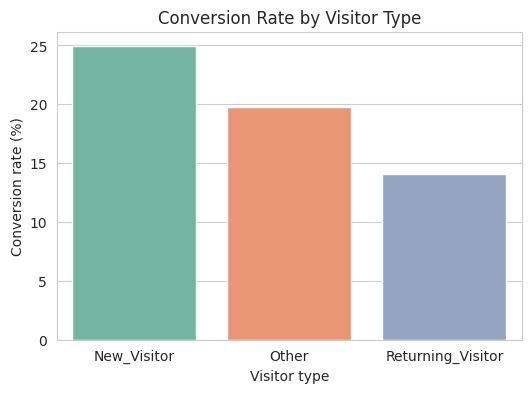

In [ ]:
visitor_rate = df.groupby('Visitor_Type')['Purchased'].mean() * 100

plt.figure(figsize=(6, 4))
sns.barplot(x=visitor_rate.index, y=visitor_rate.values, palette='Set2')
plt.title('Conversion Rate by Visitor Type')
plt.xlabel('Visitor type')
plt.ylabel('Conversion rate (%)')
plt.show()

**Interpretation:** New visitors convert at about 24.9% and returning visitors at only 14.1%. Returning visitors are the majority but they buy less per session, which I did not expect.

**Chart 7 - Page value for buyers and non-buyers**

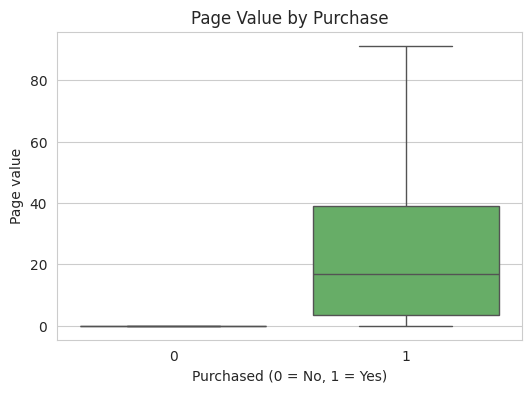

In [ ]:
plt.figure(figsize=(6, 4))
sns.boxplot(x='Purchased', y='Page_Value', data=df, showfliers=False, palette=['#d9534f', '#5cb85c'])
plt.title('Page Value by Purchase')
plt.xlabel('Purchased (0 = No, 1 = Yes)')
plt.ylabel('Page value')
plt.show()

In [ ]:
# page value is not normally distributed, so Mann-Whitney test is used
buyers = df[df['Purchased'] == 1]['Page_Value']
non_buyers = df[df['Purchased'] == 0]['Page_Value']

print('Average page value - buyers:', round(buyers.mean(), 1), '| non-buyers:', round(non_buyers.mean(), 1))
print('Median page value - buyers:', round(buyers.median(), 1), '| non-buyers:', round(non_buyers.median(), 1))
print(stats.mannwhitneyu(buyers, non_buyers))

Average page value - buyers: 27.3 | non-buyers: 2.0
Median page value - buyers: 16.8 | non-buyers: 0.0
MannwhitneyuResult(statistic=np.float64(16951382.0), pvalue=np.float64(0.0))


**Interpretation:** Buyers have a much higher page value. The average is about 27 for buyers and 2 for non-buyers, and the median for non-buyers is 0. The p-value of the test is almost 0, so the difference is real and not by chance.

**Chart 8 - Bounce rate vs exit rate**

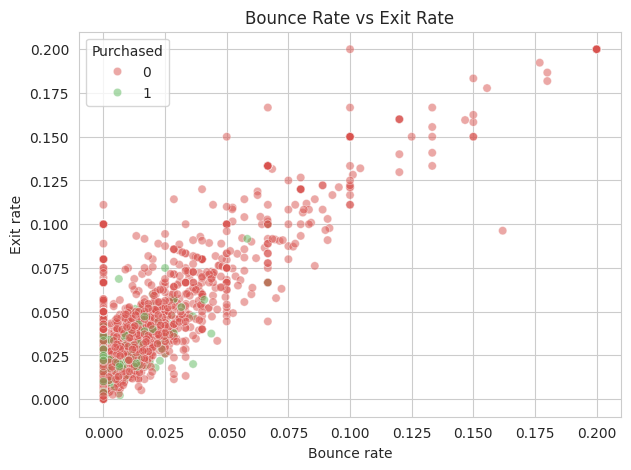

Correlation: 0.9


In [ ]:
plt.figure(figsize=(7, 5))
sns.scatterplot(x='Bounce_Rate', y='Exit_Rate', hue='Purchased',
                data=df.sample(3000, random_state=1), alpha=0.5, palette=['#d9534f', '#5cb85c'])
plt.title('Bounce Rate vs Exit Rate')
plt.xlabel('Bounce rate')
plt.ylabel('Exit rate')
plt.show()

print('Correlation:', round(df['Bounce_Rate'].corr(df['Exit_Rate']), 2))

**Interpretation:** Both rates increase together (correlation is about 0.90). The buyers are mostly at the bottom left, which means low bounce and low exit go with a purchase.

**Chart 9 - Correlation heatmap**

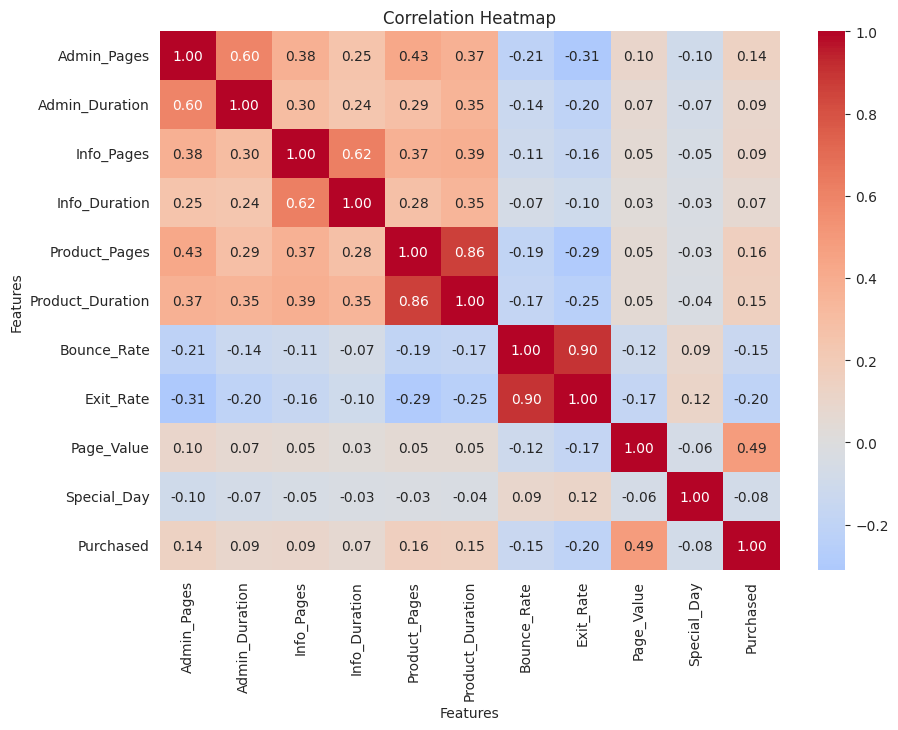

In [ ]:
corr_cols = ['Admin_Pages', 'Admin_Duration', 'Info_Pages', 'Info_Duration', 'Product_Pages',
             'Product_Duration', 'Bounce_Rate', 'Exit_Rate', 'Page_Value', 'Special_Day', 'Purchased']

plt.figure(figsize=(10, 7))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Heatmap')
plt.xlabel('Features')
plt.ylabel('Features')
plt.show()

**Interpretation:** Page_Value has the highest correlation with Purchased (0.49). Product_Pages and Product_Duration are weakly positive (around 0.15), while Exit_Rate (-0.20) and Bounce_Rate (-0.15) are negative, so more exits and bounces mean fewer purchases. Correlation does not prove that one thing causes the other.

**Chart 10 - Special day, weekend and region**

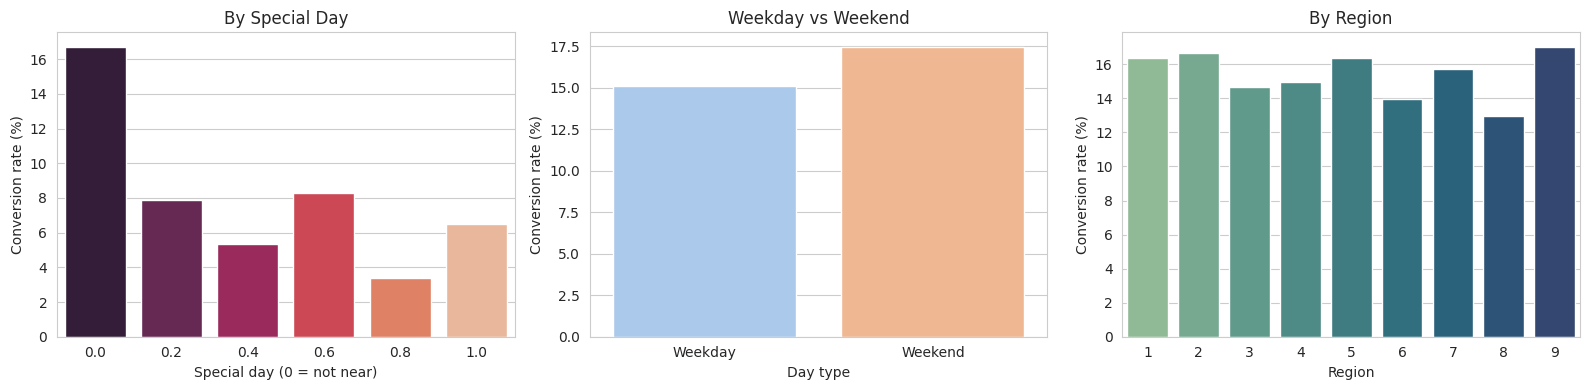

In [ ]:
special_rate = df.groupby('Special_Day')['Purchased'].mean() * 100
weekend_rate = df.groupby('Weekend')['Purchased'].mean() * 100
region_rate = df.groupby('Region')['Purchased'].mean() * 100

fig, ax = plt.subplots(1, 3, figsize=(16, 4))

sns.barplot(x=special_rate.index, y=special_rate.values, palette='rocket', ax=ax[0])
ax[0].set_title('By Special Day')
ax[0].set_xlabel('Special day (0 = not near)')
ax[0].set_ylabel('Conversion rate (%)')

sns.barplot(x=['Weekday', 'Weekend'], y=weekend_rate.values, palette='pastel', ax=ax[1])
ax[1].set_title('Weekday vs Weekend')
ax[1].set_xlabel('Day type')
ax[1].set_ylabel('Conversion rate (%)')

sns.barplot(x=region_rate.index.astype(str), y=region_rate.values, palette='crest', ax=ax[2])
ax[2].set_title('By Region')
ax[2].set_xlabel('Region')
ax[2].set_ylabel('Conversion rate (%)')

plt.tight_layout()
plt.show()

**Interpretation:** Normal days convert at about 16.7% but days close to a special day only convert at 3% to 8%, which is the opposite of what I expected. Maybe people just browse for gifts and buy later. Weekends are slightly better (17.5%) than weekdays (15.1%), and all 9 regions are between 13% and 17%, so region and day of the week do not make much difference.

**Chart 11 - Conversion rate by traffic type**

In [ ]:
# only traffic types with 100 or more sessions, small groups can give a fake 0% or 100%
traffic = df.groupby('Traffic_Type').agg(rate=('Purchased', 'mean'), sessions=('Purchased', 'size'))
traffic = traffic[traffic['sessions'] >= 100].sort_values('rate', ascending=False)
traffic.round(3)

,rate,sessions
Traffic_Type,,
8,0.277,343
20,0.259,193
2,0.217,3911
5,0.215,260
10,0.200,450
11,0.190,247
4,0.155,1066
6,0.120,443
1,0.110,2388


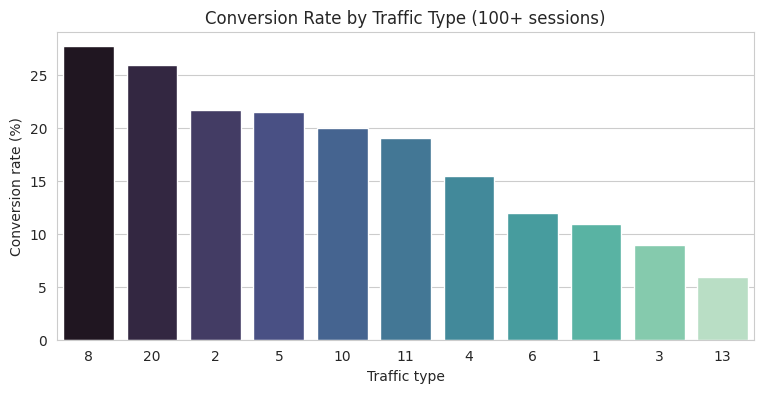

In [ ]:
plt.figure(figsize=(9, 4))
sns.barplot(x=traffic.index.astype(str), y=traffic['rate'] * 100, palette='mako')
plt.title('Conversion Rate by Traffic Type (100+ sessions)')
plt.xlabel('Traffic type')
plt.ylabel('Conversion rate (%)')
plt.show()

**Interpretation:** I kept only the traffic types with 100 or more sessions. Types 8, 20, 2, 5 and 10 convert best (about 20% to 28%), while types 13, 3 and 1 convert poorly (6% to 11%), even though types 1 and 3 bring a lot of traffic.

### Multivariate analysis

**Chart 12 - Month and visitor type**

In [ ]:
# Other visitors are removed because there are too few of them
known = df[df['Visitor_Type'] != 'Other']
pt = known.pivot_table(values='Purchased', index='Month', columns='Visitor_Type', aggfunc='mean').reindex(month_order) * 100
pt.round(1)

Visitor_Type,New_Visitor,Returning_Visitor
Month,,
Feb,0.0,1.7
Mar,15.5,9.6
May,27.6,9.2
June,23.3,8.7
Jul,20.4,14.6
Aug,29.2,15.2
Sep,25.9,17.1
Oct,22.6,20.5
Nov,30.5,24.8


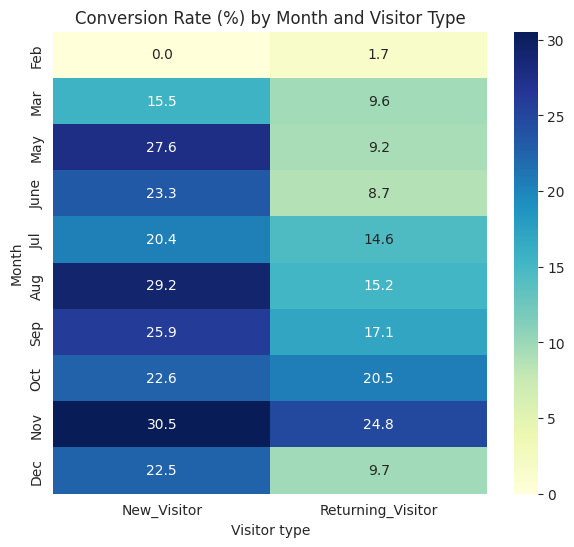

In [ ]:
plt.figure(figsize=(7, 6))
sns.heatmap(pt, annot=True, fmt='.1f', cmap='YlGnBu')
plt.title('Conversion Rate (%) by Month and Visitor Type')
plt.xlabel('Visitor type')
plt.ylabel('Month')
plt.show()

**Interpretation:** New visitors convert better than returning visitors in every month except February, where there is only 1 new visitor and that session did not buy. November is the best for both (30.5% for new and 24.8% for returning), and the gap is biggest in May (27.6% vs 9.2%).

**Chart 13 - Engagement level and visitor type**

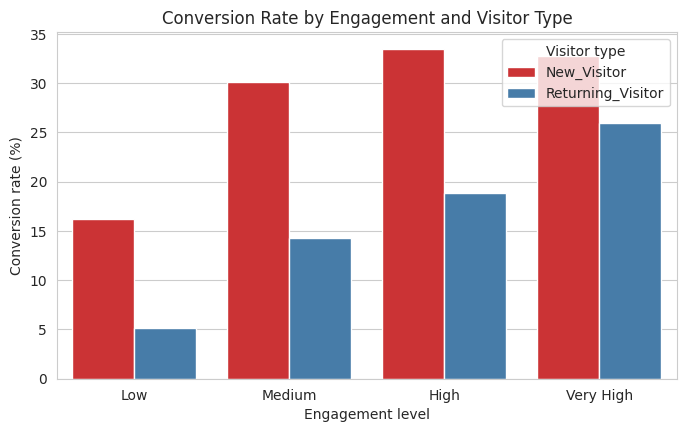

In [ ]:
eng = known.groupby(['Engagement', 'Visitor_Type'])['Purchased'].mean().reset_index()
eng['Purchased'] = eng['Purchased'] * 100

plt.figure(figsize=(8, 4.5))
sns.barplot(x='Engagement', y='Purchased', hue='Visitor_Type', data=eng, palette='Set1')
plt.title('Conversion Rate by Engagement and Visitor Type')
plt.xlabel('Engagement level')
plt.ylabel('Conversion rate (%)')
plt.legend(title='Visitor type')
plt.show()

**Interpretation:** Conversion goes up as engagement goes up, from about 7% for Low to about 26% for Very High overall. New visitors are better at every level, but for them it flattens after Medium, while returning visitors keep improving till Very High.

**Chart 14 - Pairplot**

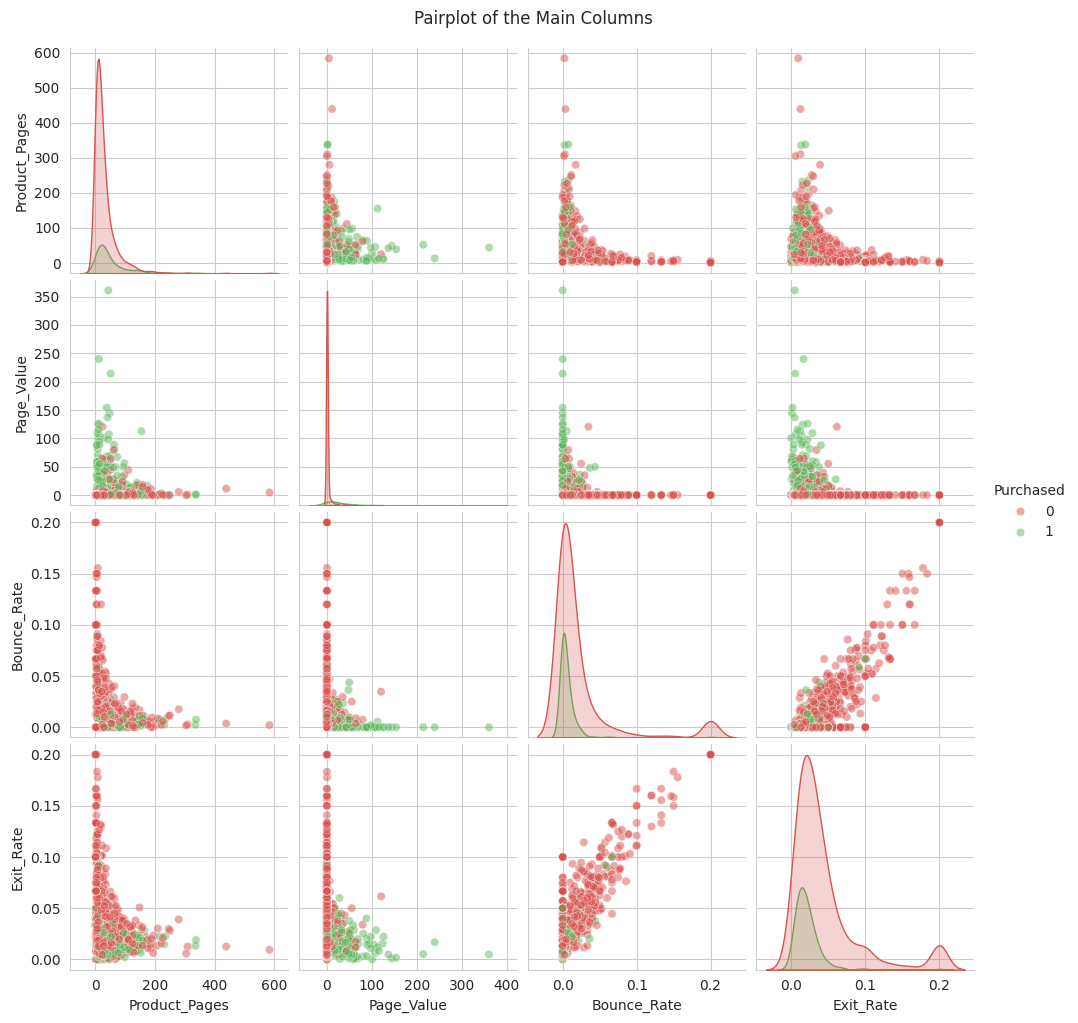

In [ ]:
pp = sns.pairplot(df.sample(1500, random_state=1),
                  vars=['Product_Pages', 'Page_Value', 'Bounce_Rate', 'Exit_Rate'],
                  hue='Purchased', palette=['#d9534f', '#5cb85c'], plot_kws={'alpha': 0.5})
pp.fig.suptitle('Pairplot of the Main Columns', y=1.02)
plt.show()

**Interpretation:** Buyers (green) are spread towards higher page value and more product pages, and stay near zero for bounce and exit rate. Non-buyers (red) are mostly near zero page value. Page value separates the two groups best.

### Page value zero vs more than zero

In [ ]:
df.groupby(df['Page_Value'] > 0)['Purchased'].agg(['mean', 'size']).round(3)

,mean,size
Page_Value,,
False,0.039,9475
True,0.563,2730


About 78% of the sessions have a page value of 0 and only about 4% of them buy. When the page value is above 0, about 56% buy. This is the biggest gap in the whole analysis.

### Saving the cleaned data

In [ ]:
df.to_csv('online_shoppers_cleaned.csv', index=False)

## Task 4 - Insights and Conclusion

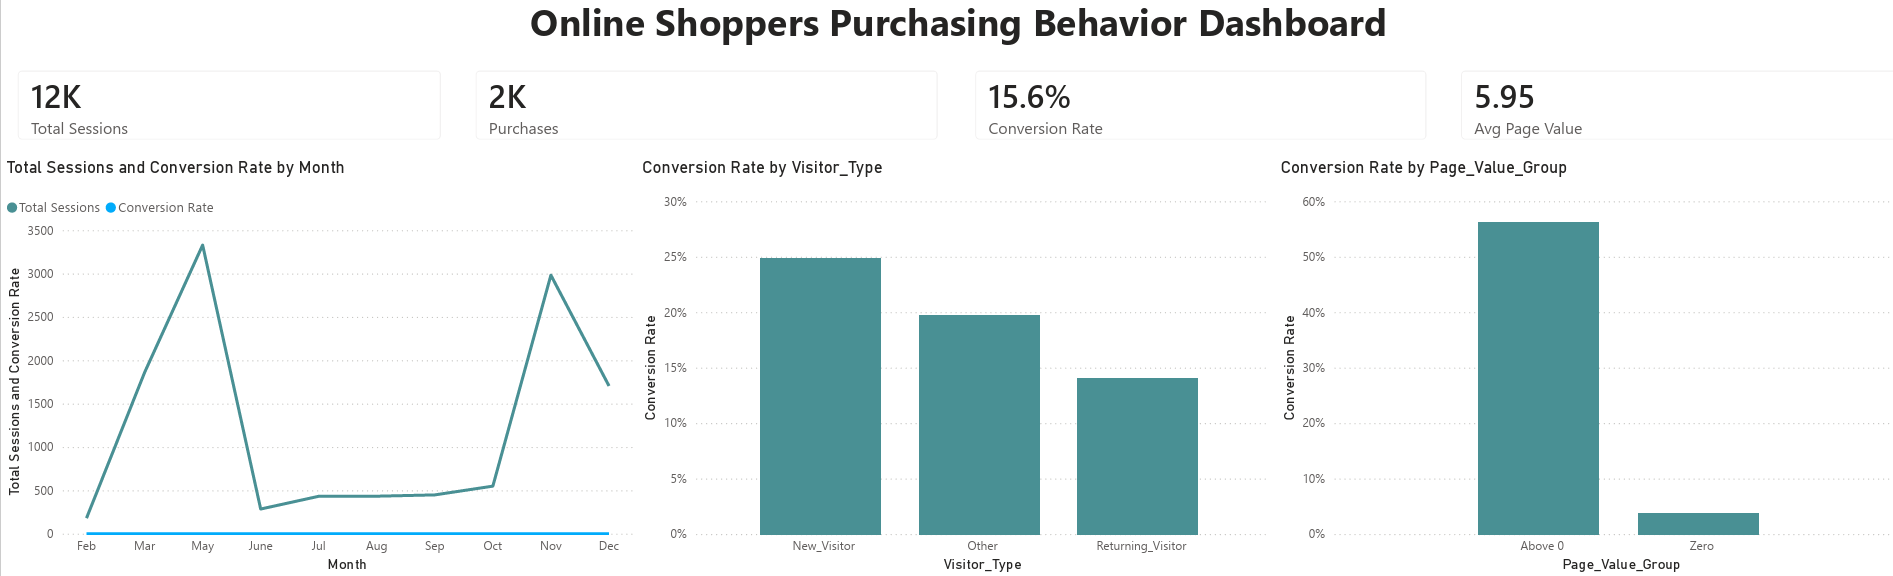

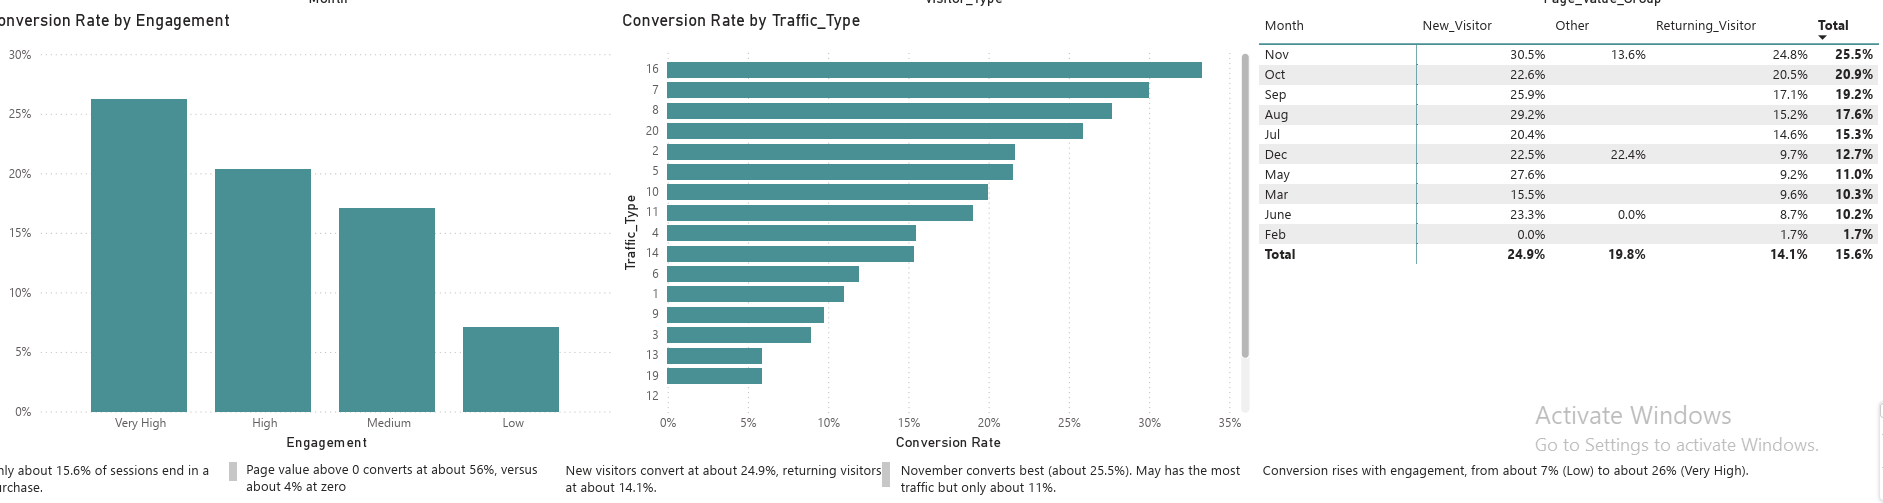

In [ ]:
from IPython.display import display, Image

display(Image(filename='/content/dashboard1.PNG'))

display(Image(filename='/content/dashboard2.PNG'))


### Key insights
1. Only about 15.6% of the sessions end in a purchase.
2. Page value is the strongest factor. Sessions with a page value above 0 convert at about 56% and the ones with 0 at about 4%.
3. New visitors convert more (about 25%) than returning visitors (about 14%), even though returning visitors are 85% of the traffic.
4. November, October and September are the best months. May has the most traffic but low conversion, and February is almost zero.
5. High bounce and exit rates mean fewer purchases, and more product pages viewed means more purchases (7% for low engagement vs 26% for very high).
6. Visits near a special day convert less, and some traffic types (1, 3 and 13) bring many visitors but few buyers.

### Recommendations
- Push the pages with a high page value so more sessions reach them.
- Improve the landing pages for the sources with a high bounce rate.
- Run offers in May and February, and keep stock ready for November.
- Find out why returning visitors buy less and try loyalty offers.
- Review the money spent on traffic types 1, 3 and 13.

### Conclusion
I cleaned the data by removing duplicates, fixing the data types and adding new columns, and then studied it with 14 chart cells. The main finding is that page value and engagement have the strongest link with buying, new visitors convert better than returning visitors, and November is the strongest month. So the shop should focus on its high value pages, better landing pages and offers in the weak months.

### Limitations and next steps
- The data covers only one year and January and April are missing.
- Region, Browser and Traffic Type are only codes, so we do not know what they really are.
- Each row is one session and not one customer.
- Next, I can build a dashboard in Power BI with the cleaned file and try a model to predict if a session will end in a purchase.